# 03. Etapa II: LLM via prompting

Zero-shot e few-shot com 3, 5, 10 e 20 exemplos, na mesma amostra fixa de 200 casos usada para os clássicos. O provedor e a chave vêm do arquivo `.env` (modelo em `.env.example`). Código: `src/run_llm.py` e `src/llm/`.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)  # comandos python -m src.* rodam a partir da raiz
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, Markdown, display
from src import config as C
pd.set_option("display.max_columns", 30)
from dotenv import load_dotenv
load_dotenv(ROOT / '.env')
print('provedor:', os.getenv('LLM_PROVIDER'), '| modelo:', os.getenv('LLM_MODEL') or '(padrão)')

provedor: deepseek | modelo: (padrão)


## 1. Conferir o prompt (não chama a API)

In [2]:
!"{sys.executable}" -m src.run_llm --dry-run --k 0 3


============================== k=0 ==============================
[SYSTEM]
Você é um engenheiro de manutenção especialista em máquinas de usinagem (fresadoras).
Sua tarefa é classificar se uma máquina vai FALHAR (1) ou NÃO falhar (0) a partir de leituras de sensores de um ciclo de operação.

Atributos de cada leitura:
- Tipo: qualidade do produto em fabricação (L = baixa, M = média, H = alta)
- Temperatura do ar [K]
- Temperatura do processo [K]
- Rotação [rpm]
- Torque [Nm]
- Desgaste da ferramenta [min]: tempo acumulado de uso da ferramenta

Responda SOMENTE com um JSON de uma linha, sem texto antes ou depois, no formato:
{"falha": 0 ou 1, "probabilidade": número entre 0 e 1 com a sua confiança de que haverá falha}

[USER]
Classifique esta leitura:
Tipo: M | Temperatura do ar: 299.0 K | Temperatura do processo: 310.3 K | Rotação: 1657 rpm | Torque: 31.0 Nm | Desgaste da ferramenta: 70 min

============================== k=3 ==============================
[SYSTEM]
Você é um engenheir

## 2. Teste com 10 casos

In [3]:
!"{sys.executable}" -m src.run_llm --limit 10 --k 0

Provedor=deepseek  modelo=deepseek-chat  prompt=v1  casos=10
   k= 0 acc=0.600 prec=0.400 rec=0.667 f1=0.500 auc=0.6667 inválidas=0 t/100=135.05s custo=$0.0005

Resultados em reports\results



k=0: 100%|██████████| 10/10 [00:00<00:00, 2468.98it/s]


## 3. Rodada completa

As respostas ficam em cache: se a execução cair no meio, basta rodar de novo.

In [4]:
!"{sys.executable}" -m src.run_llm

Provedor=deepseek  modelo=deepseek-chat  prompt=v1  casos=200
   k= 0 acc=0.550 prec=0.341 rec=0.860 f1=0.489 auc=0.721 inválidas=0 t/100=97.74s custo=$0.0101
   k= 3 acc=0.700 prec=0.446 rec=0.820 f1=0.578 auc=0.8034 inválidas=0 t/100=95.27s custo=$0.0161
   k= 5 acc=0.665 prec=0.419 rec=0.880 f1=0.568 auc=0.8024 inválidas=0 t/100=97.94s custo=$0.0199
   k=10 acc=0.765 prec=0.518 rec=0.880 f1=0.652 auc=0.8503 inválidas=0 t/100=94.99s custo=$0.0295
   k=20 acc=0.810 prec=0.597 rec=0.740 f1=0.661 auc=0.8432 inválidas=0 t/100=96.62s custo=$0.0487

Resultados em reports\results



k=0: 100%|██████████| 200/200 [00:00<00:00, 4012.61it/s]

k=3: 100%|██████████| 200/200 [00:00<00:00, 760.00it/s]

k=5: 100%|██████████| 200/200 [00:00<00:00, 570.67it/s]

k=10: 100%|██████████| 200/200 [00:00<00:00, 365.83it/s]

k=20: 100%|██████████| 200/200 [00:00<00:00, 206.00it/s]


## 4. Resultados

In [5]:
res = pd.read_csv(C.RESULTS / 'summary.csv')
llm = res[(res['stage'] == 'II') & (res['eval_set'] == 'eval_sample')]
llm[['model', 'setting', 'accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'invalid_answers', 'time_per_100_s', 'cost_per_100_usd']]

,model,setting,accuracy,precision,recall,f1,roc_auc,invalid_answers,time_per_100_s,cost_per_100_usd
29,deepseek:deepseek-chat,zero-shot,0.550,0.3413,0.86,0.4886,0.7210,0.0,97.74,0.00504
30,deepseek:deepseek-chat,few-shot k=3,0.700,0.4457,0.82,0.5775,0.8034,0.0,95.27,0.00804
31,deepseek:deepseek-chat,few-shot k=5,0.665,0.4190,0.88,0.5677,0.8024,0.0,97.94,0.00996
32,deepseek:deepseek-chat,few-shot k=10,0.765,0.5176,0.88,0.6519,0.8503,0.0,94.99,0.01476
33,deepseek:deepseek-chat,few-shot k=20,0.810,0.5968,0.74,0.6607,0.8432,0.0,96.62,0.02436


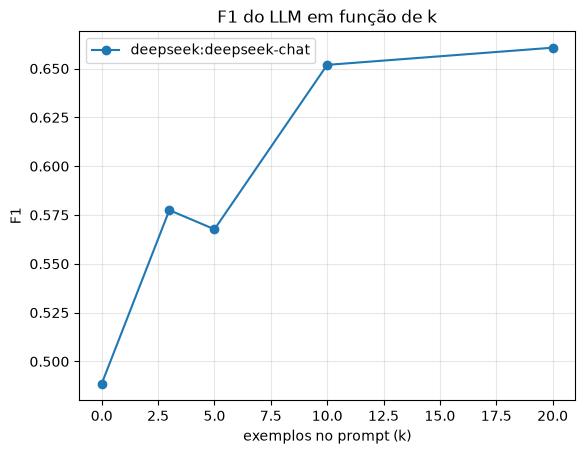

In [6]:
k = llm['setting'].map(lambda s: 0 if s == 'zero-shot' else int(s.split('=')[1]))
for model, g in llm.assign(k=k).sort_values('k').groupby('model'):
    plt.plot(g['k'], g['f1'], marker='o', label=model)
plt.xlabel('exemplos no prompt (k)'); plt.ylabel('F1'); plt.legend(); plt.grid(alpha=.3)
plt.title('F1 do LLM em função de k')
plt.savefig(C.FIGURES / 'llm_f1_vs_k.png', dpi=150, bbox_inches='tight'); plt.show()

## 5. Erros do LLM

Casos em que o LLM (zero-shot) errou, com o modo de falha registrado na base (TWF, HDF, PWF, OSF, RNF).

In [7]:
import glob
arquivos = sorted(glob.glob(str(C.RESULTS / 'llm_*_predictions.csv')))
print(*[Path(a).name for a in arquivos], sep='\n')
if arquivos:
    pred = pd.read_csv(arquivos[0])
    amostra = pd.read_csv(C.DATA_PROCESSED / 'eval_sample.csv')
    erros = pred.merge(amostra, on='UDI').query('y_true != y_pred')
    display(erros[['UDI', 'y_true', 'y_pred', 'prob'] + C.FAILURE_MODE_COLS].head(20))

llm_deepseek_deepseek-chat_k0_predictions.csv
llm_deepseek_deepseek-chat_k10_predictions.csv
llm_deepseek_deepseek-chat_k20_predictions.csv
llm_deepseek_deepseek-chat_k3_predictions.csv
llm_deepseek_deepseek-chat_k5_predictions.csv


,UDI,y_true,y_pred,prob,TWF,HDF,PWF,OSF,RNF
2,381,1,0,0.12,0,0,1,0,0
4,6564,0,1,0.82,0,0,0,0,0
5,4867,0,1,0.72,0,0,0,0,0
6,2577,0,1,0.82,0,0,0,0,0
14,4878,0,1,0.72,0,0,0,0,0
15,8420,0,1,0.82,0,0,0,0,0
16,2161,0,1,0.82,0,0,0,0,0
19,8749,0,1,0.82,0,0,0,0,0
20,7685,0,1,0.82,0,0,0,0,0
24,3576,0,1,0.82,0,0,0,0,0
